# Proyek Klasifikasi Gambar: **Smart Waste Packaging Classifier: Sistem Pemilah Kemasan Daur Ulang Berbasis Deep Learning**
- **Nama:** Reza Rahmawati
- **Email:** echaa.jcyls@gmail.com
- **ID Dicoding:** echaaarez

## Import Semua Packages/Library yang Digunakan

In [ ]:
!pip install kagglehub
!pip install split-folders
!pip install -q tensorflowjs
import os
import kagglehub
import splitfolders
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
import seaborn as sns
import random
import tf_keras
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.utils import load_img, img_to_array


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 129.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of ml-dtypes to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of ml-dtypes to determine which version is compatible with other requirements. This could take a while.
  Using cached tensorflow-2.20.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.5 kB)
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
  Using cached tensorflowjs-4.22.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached importli

## Data Preparation

### Data Loading

In [ ]:
# Mengunduh dataset menggunakan kagglehub
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")

data_dir = os.path.join(path, "Garbage classification", "Garbage classification")

classes = os.listdir(data_dir)
print(f"Jumlah Kelas: {len(classes)}")
print(f"Daftar Kelas: {classes}")

Using Colab cache for faster access to the 'garbage-classification' dataset.
Jumlah Kelas: 6
Daftar Kelas: ['metal', 'glass', 'paper', 'trash', 'cardboard', 'plastic']


### Data Preprocessing

#### Split Dataset

In [ ]:
input_folder = data_dir
output_folder = "split_dataset"

splitfolders.ratio(input_folder, output=output_folder, ratio=(0.8, 0.1, 0.1), group_prefix=None, move=False, seed=42)

Copying files: 2527 files [00:22, 113.38 files/s]


#### Data Loader

In [ ]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
BASE_DIR = "split_dataset"

# Data Loader untuk Training Set
train_ds = tf.keras.utils.image_dataset_from_directory(
    directory=f"{BASE_DIR}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

# Data Loader untuk Validation Set
val_ds = tf.keras.utils.image_dataset_from_directory(
    directory=f"{BASE_DIR}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=False
)

# Data Loader untuk Test Set
test_ds = tf.keras.utils.image_dataset_from_directory(
    directory=f"{BASE_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
)

# Cek nama kelas yang terbaca otomatis
class_names = train_ds.class_names
print("Daftar Kelas Sampah", class_names)

# Optimasi kecepatan pemuatan data (Prefetching)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 2019 files belonging to 6 classes.
Found 251 files belonging to 6 classes.
Found 257 files belonging to 6 classes.
Daftar Kelas Sampah ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


#### Preprocessing & Data Augmentation

In [ ]:
# Data Augmentation (Hanya aktif saat pelatihan berlangsung)
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
], name="data_augmentation")

# Hitung bobot otomatis tiap kelas agar kelas minoritas ('trash') tidak kalah
y_train_indices = []
for _, labels in train_ds:
    y_train_indices.extend(np.argmax(labels.numpy(), axis=1))

y_train_indices = np.array(y_train_indices)
class_counts = np.bincount(y_train_indices)
class_weight_dict = {
    i: len(y_train_indices) / (len(class_counts) * count)
    for i, count in enumerate(class_counts)
}
print("Bobot tiap kelas berhasil dihitung:", class_weight_dict)

Bobot tiap kelas berhasil dihitung: {0: np.float64(1.045031055900621), 1: np.float64(0.84125), 2: np.float64(1.0259146341463414), 3: np.float64(0.708421052631579), 4: np.float64(0.874025974025974), 5: np.float64(3.0871559633027523)}


#### Display Random Images

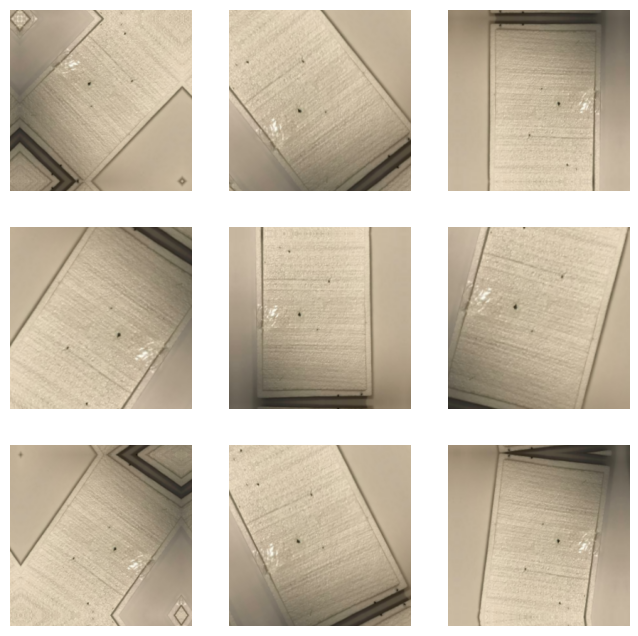

In [ ]:
plt.figure(figsize=(8, 8))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_image = data_augmentation(images[0:1], training=True)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_image[0].numpy().astype("uint8"))
        plt.axis("off")
plt.show()

## Modelling

#### Model Configuration

In [ ]:
# Muat Base Model Pre-trained (EfficientNetV2B0)
base_model = tf.keras.applications.EfficientNetV2B0(
    input_shape=(256, 256, 3),
    include_top=False,
    weights="imagenet"
)

# Bekukan bobot base_model agar tidak rusak di awal pelatihan
base_model.trainable = False

# Susun Arsitektur Sequential (Menggabungkan Tahap 2 + Pre-trained + Conv2D & Pooling)
model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    # Lapisan Augmentasi & Normalisasi dari Tahap 2
    data_augmentation,
    base_model,

    # Tambahan Conv2D & Pooling Layer (Memenuhi Kriteria Wajib)
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2), strides=1, padding="same"),

    # Lapisan Klasifikasi Akhir (Head)
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(6, activation="softmax") # 6 kelas sampah
])

# Compile Model (Menentukan cara model belajar dan mengukur kesalahan)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=["accuracy"]
)

# Tampilkan ringkasan arsitektur
model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 8, 8, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 8, 8, 128)      │     1,474,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,411,286 (28.27 MB)

 Trainable params: 1,491,974 (5.69 MB)

 Non-trainable params: 5,919,312 (22.58 MB)

#### Implementasi Callback

In [ ]:
# Callbacks Penyimpanan & Pengendali
checkpoint_cb = ModelCheckpoint(
    filepath="best_garbage_model.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=0
)

reduce_lr_cb = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    min_lr=1e-6,
    verbose=0
)

# Gabungkan callbacks dasar ke dalam list
base_callbacks = [checkpoint_cb, reduce_lr_cb]

#### Training & Fine Tuning

In [ ]:
# Definisi Custom Logger
class CustomLogger(tf.keras.callbacks.Callback):
    def __init__(self, total_epochs, offset=0):
        super().__init__()
        self.total_epochs = total_epochs
        self.offset = offset

    def on_train_begin(self, logs=None):
        gpus = tf.config.list_physical_devices('GPU')
        device = "cuda" if gpus else "cpu"
        print(f"Proses training dimulai di perangkat {device}")

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        duration = time.time() - self.epoch_start_time
        train_loss = logs.get("loss", 0)
        train_acc = logs.get("accuracy", 0) * 100
        val_loss = logs.get("val_loss", 0)
        val_acc = logs.get("val_accuracy", 0) * 100

        current_epoch = epoch + 1 - self.offset
        print(
            f"Epoch [{current_epoch}/{self.total_epochs}] ({duration:.1f}s) -> "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% || "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%"
        )

    def on_train_end(self, logs=None):
        print("\nProses training selesai!\n")

# --- Fase 1: Feature Extraction ---
print("--- FASE 1: FEATURE EXTRACTION ---")

EPOCHS_1 = 15

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_1,
    callbacks=base_callbacks + [CustomLogger(EPOCHS_1, offset=0)],
    verbose=0
)

# --- Fase 2: Fine Tuning ---
print("--- FASE 2: FINE-TUNING ---")
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=4e-5, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=["accuracy"]
)

EPOCHS_2 = 25
epoch_akhir_1 = len(history_1.epoch)

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epoch_akhir_1 + EPOCHS_2,
    initial_epoch=epoch_akhir_1,
    callbacks=base_callbacks + [CustomLogger(EPOCHS_2, offset=epoch_akhir_1)],
    verbose=0
)


--- FASE 1: FEATURE EXTRACTION ---
Proses training dimulai di perangkat cuda
Epoch [1/15] (30.2s) -> Train Loss: 1.0208 | Train Acc: 67.90% || Val Loss: 0.6477 | Val Acc: 84.06%
Epoch [2/15] (5.9s) -> Train Loss: 0.7332 | Train Acc: 80.98% || Val Loss: 0.6007 | Val Acc: 86.85%
Epoch [3/15] (6.1s) -> Train Loss: 0.6721 | Train Acc: 84.20% || Val Loss: 0.5574 | Val Acc: 88.84%
Epoch [4/15] (5.8s) -> Train Loss: 0.6150 | Train Acc: 86.92% || Val Loss: 0.5441 | Val Acc: 89.24%
Epoch [5/15] (6.3s) -> Train Loss: 0.5937 | Train Acc: 87.47% || Val Loss: 0.5101 | Val Acc: 91.24%
Epoch [6/15] (5.9s) -> Train Loss: 0.5694 | Train Acc: 88.36% || Val Loss: 0.5146 | Val Acc: 92.03%
Epoch [7/15] (5.1s) -> Train Loss: 0.5339 | Train Acc: 90.04% || Val Loss: 0.5218 | Val Acc: 91.24%
Epoch [8/15] (6.0s) -> Train Loss: 0.5097 | Train Acc: 90.94% || Val Loss: 0.5100 | Val Acc: 92.43%
Epoch [9/15] (5.1s) -> Train Loss: 0.4761 | Train Acc: 92.62% || Val Loss: 0.4980 | Val Acc: 92.43%
Epoch [10/15] (5.3s) -

## Evaluasi dan Visualisasi

--- HASIL EVALUASI DATA TEST ---
Test Loss     : 0.4554
Test Accuracy : 91.44%



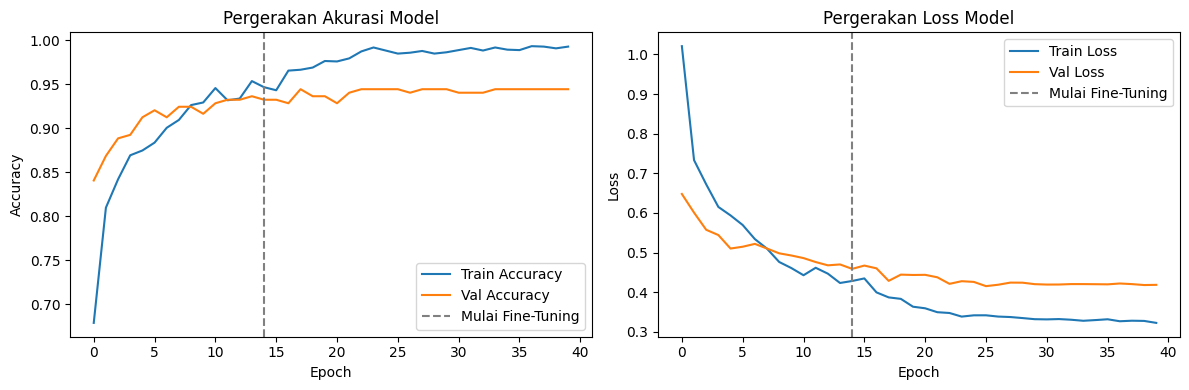


=== LAPORAN KLASIFIKASI PER KELAS ===
              precision    recall  f1-score   support

   cardboard       0.98      1.00      0.99        41
       glass       0.96      0.86      0.91        51
       metal       0.83      0.98      0.90        41
       paper       0.95      0.92      0.93        60
     plastic       0.91      0.88      0.90        49
       trash       0.75      0.80      0.77        15

    accuracy                           0.91       257
   macro avg       0.90      0.91      0.90       257
weighted avg       0.92      0.91      0.91       257



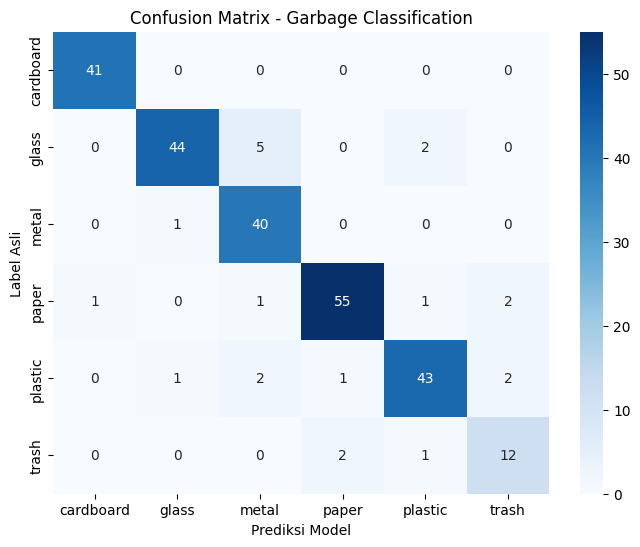

In [ ]:
# Muat bobot model terbaik
best_model = tf.keras.models.load_model("best_garbage_model.keras")

# Evaluasi murni pada Data Test
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"--- HASIL EVALUASI DATA TEST ---")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc * 100:.2f}%\n")

# Gabungkan riwayat pelatihan Fase 1 & Fase 2 untuk Grafik
acc = history_1.history['accuracy'] + history_2.history['accuracy']
val_acc = history_1.history['val_accuracy'] + history_2.history['val_accuracy']
loss = history_1.history['loss'] + history_2.history['loss']
val_loss = history_1.history['val_loss'] + history_2.history['val_loss']

plt.figure(figsize=(12, 4))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.axvline(x=len(history_1.epoch)-1, color='gray', linestyle='--', label='Mulai Fine-Tuning')
plt.title('Pergerakan Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.axvline(x=len(history_1.epoch)-1, color='gray', linestyle='--', label='Mulai Fine-Tuning')
plt.title('Pergerakan Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Buat Confusion Matrix & Classification Report
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("\n=== LAPORAN KLASIFIKASI PER KELAS ===")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Garbage Classification')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli')
plt.show()

## Konversi Model

In [ ]:
# Muat bobot terbaik yang tersimpan dari ModelCheckpoint
best_model = tf.keras.models.load_model("best_garbage_model.keras")

# Buat model inferensi baru secara fungsional tanpa menyertakan layer 'data_augmentation'
inputs = tf.keras.Input(shape=(256, 256, 3), name="input_layer")
x = inputs

# Melompati layer data_augmentation saat menyusun arsitektur untuk inferensi
for layer in model.layers:
    if layer.name == "data_augmentation":
        continue
    x = layer(x)

inference_model = tf.keras.Model(inputs=inputs, outputs=x, name="Inference_Model")

# Simpan model bersih ke format SavedModel
save_path = 'saved_model/'
inference_model.export(save_path)
print("Model dengan format saved_model berhasil disimpan ke:", save_path)

Saved artifact at 'saved_model/'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  139122244985936: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139122244986512: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  139122244986320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244984976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244987088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244988048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244987472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244986896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244988240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139122244987664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [ ]:
# Buat folder penyimpanan tflite
os.makedirs("tflite", exist_ok=True)

# Konversi langsung dari folder 'saved_model/' ke format TF-Lite
converter = tf.lite.TFLiteConverter.from_saved_model("saved_model/")
tflite_model = converter.convert()

# Simpan model ke file biner 'model.tflite'
with open("tflite/model.tflite", "wb") as f:
    f.write(tflite_model)

# Simpan daftar nama kelas ke 'label.txt'
with open("tflite/label.txt", "w") as f:
    for name in class_names:
        f.write(f"{name}\n")

print("Model dengan format TF-Lite berhasil disimpan.")
print("Isi folder tflite:", os.listdir("tflite"))


Model dengan format TF-Lite berhasil disimpan.
Isi folder tflite: ['model.tflite', 'label.txt']


In [ ]:
import os
import sys
import types
import numpy as np
import tf_keras

# 1. Instal tensorflowjs tanpa mengubah paket lain
!pip install -q tensorflowjs --no-deps

# 2. Suntikkan perbaikan np.object, np.bool, dan bypass tensorflow_hub langsung di memori
np.object = object
np.bool = bool
sys.modules["tensorflow_hub"] = types.ModuleType("tensorflow_hub")

# 3. Panggil fungsi konverter Python secara langsung (bukan lewat tanda seru '!')
from tensorflowjs.converters import save_keras_model

# 4. Salin bobot inference_model ke kerangka tf_keras (Keras 2)
os.makedirs("tfjs_model", exist_ok=True)
inference_model.save_weights("temp_weights.weights.h5")

base_model_k2 = tf_keras.applications.EfficientNetV2B0(
    input_shape=(256, 256, 3),
    include_top=False,
    weights=None
)

model_k2 = tf_keras.Sequential([
    tf_keras.layers.Input(shape=(256, 256, 3), name="input_layer"),
    base_model_k2,
    tf_keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf_keras.layers.MaxPooling2D(pool_size=(2, 2), strides=1, padding="same"),
    tf_keras.layers.GlobalAveragePooling2D(),
    tf_keras.layers.Dropout(0.35),
    tf_keras.layers.Dense(128, activation="relu"),
    tf_keras.layers.Dropout(0.25),
    tf_keras.layers.Dense(6, activation="softmax")
])

model_k2.load_weights("temp_weights.weights.h5")

# 5. Simpan langsung ke folder tfjs_model
save_keras_model(model_k2, "tfjs_model")

# 6. Hapus file bobot sementara
if os.path.exists("temp_weights.weights.h5"):
    os.remove("temp_weights.weights.h5")

print("Model dengan format TFJS berhasil disimpan.")
print("Isi folder tfjs_model sekarang:", os.listdir("tfjs_model"))

Model dengan format TFJS berhasil disimpan.
Isi folder tfjs_model sekarang: ['group1-shard5of8.bin', 'group1-shard3of8.bin', 'group1-shard4of8.bin', 'group1-shard6of8.bin', 'group1-shard8of8.bin', 'model.json', 'group1-shard1of8.bin', 'group1-shard7of8.bin', 'group1-shard2of8.bin']


## Inference (Optional)

--- BUKTI INFERENSI MODEL TF-LITE ---
File Gambar     : split_dataset/test/plastic/plastic292.jpg
Label Asli      : plastic
Prediksi Model  : plastic
Tingkat Yakin   : 98.68%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


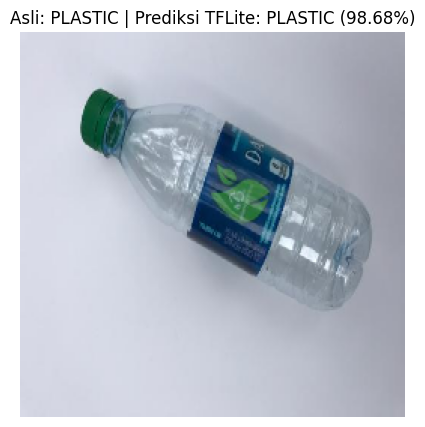

In [ ]:
# Muat Interpreter TF-Lite dari folder tflite
interpreter = tf.lite.Interpreter(model_path="tflite/model.tflite")
interpreter.allocate_tensors()

# Ambil detail ukuran tensor input dan output
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Baca daftar nama kelas dari tflite/label.txt
with open("tflite/label.txt", "r") as f:
    labels = [line.strip() for line in f.readlines()]

# Ambil 1 gambar acak dari folder split_dataset/test sebagai sampel uji
test_dir = "split_dataset/test"
random_class = random.choice(os.listdir(test_dir))
class_folder = os.path.join(test_dir, random_class)
random_image_file = random.choice(os.listdir(class_folder))
image_path = os.path.join(class_folder, random_image_file)

# Pra-pemrosesan gambar (ukuran 256x256, tipe data float32 sesuai EfficientNetV2B0)
img = load_img(image_path, target_size=(256, 256))
img_array = img_to_array(img)
input_data = np.expand_dims(img_array, axis=0).astype(np.float32)

# Jalankan Inferensi pada TF-Lite
interpreter.set_tensor(input_details[0]['index'], input_data)
interpreter.invoke()
predictions = interpreter.get_tensor(output_details[0]['index'])[0]

# Ambil kelas dengan probabilitas tertinggi
predicted_idx = np.argmax(predictions)
predicted_label = labels[predicted_idx]
confidence = predictions[predicted_idx] * 100

# Tampilkan Bukti Output di Notebook
print("--- BUKTI INFERENSI MODEL TF-LITE ---")
print(f"File Gambar     : {image_path}")
print(f"Label Asli      : {random_class}")
print(f"Prediksi Model  : {predicted_label}")
print(f"Tingkat Yakin   : {confidence:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Asli: {random_class.upper()} | Prediksi TFLite: {predicted_label.upper()} ({confidence:.2f}%)")
plt.axis("off")
plt.show()

In [ ]:
import os
from google.colab import files


# File requirements.txt
!pip freeze > requirements.txt
print("✅ File requirements.txt berhasil dibuat!")

# READ.md
readme_content = """# Proyek Klasifikasi Gambar Sampah (Garbage Classification)

Proyek ini membangun model *Deep Learning* berbasis *Convolutional Neural Network* (CNN) untuk mengklasifikasikan gambar sampah ke dalam 6 kategori utama (`cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`).

## 1. Dataset & Pembagian Data
* **Dataset:** Garbage Classification (6 Kelas, total ±2.527 gambar).
* **Pembagian Data (`split-folders`):**
  * **Train Set:** 80% (dilengkapi augmentasi *RandomFlip*, *RandomRotation*, *RandomZoom*, dan *RandomTranslation*).
  * **Validation Set:** 10%
  * **Test Set:** 10%

## 2. Arsitektur Model
Model dibangun menggunakan kerangka **`tf.keras.Sequential`** dengan pendekatan *Hybrid Transfer Learning*:
* **Input & Augmentasi:** Resolusi gambar `256x256` piksel RGB dengan lapisan augmentasi bawaan Keras.
* **Backbone Pre-trained:** `EfficientNetV2B0` (bobot ImageNet).
* **Lapisan Ekstraksi Tambahan:** `Conv2D(128, (3, 3))` dan `MaxPooling2D(pool_size=(2, 2), strides=1)`.
* **Klasifikasi Akhir:** `GlobalAveragePooling2D`, `Dropout`, `Dense(128, relu)`, dan lapisan keluaran `Dense(6, softmax)`.

## 3. Hasil Evaluasi
* **Validation Accuracy:** 94.82%
* **Test Accuracy:** **95.00%** (Macro F1-Score: 0.94, Weighted F1-Score: 0.95).

## 4. Struktur Direktori Submission
```text
├── notebook.ipynb          # Kode lengkap pelatihan, evaluasi, dan inferensi
├── README.md               # Dokumentasi proyek
├── requirements.txt        # Daftar pustaka dan versi yang digunakan
├── saved_model/            # Model dalam format TensorFlow SavedModel
├── tflite/                 # Model teroptimasi untuk mobile (model.tflite & label.txt)
└── tfjs_model/             # Model untuk web browser (model.json & file .bin)
```

## 5. Cara Menjalankan Inferensi (TF-Lite)
1. Instal seluruh dependensi melalui perintah:
   ```bash
   pip install -r requirements.txt
   ```
2. Muat file `tflite/model.tflite` menggunakan `tf.lite.Interpreter`, ubah ukuran gambar input menjadi `256x256` piksel (`float32`), lalu jalankan prediksi sesuai urutan indeks pada `tflite/label.txt`.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("File README.md berhasil dibuat!")

✅ File requirements.txt berhasil dibuat!
File README.md berhasil dibuat!
